# Funnel & Cohort Analysis — eCommerce Events (Cosmetics Shop)

**Question:** where does this store lose the most customers between first visit and repeat purchase, and what is it worth to fix?

**Data:** [eCommerce Events History in Cosmetics Shop](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop) (REES46). One row per user event — `view`, `cart`, `remove_from_cart`, `purchase` — from **1 Oct 2019 to 29 Feb 2020** (5 months, ~20.7M events). An event-level log like this is a close proxy for a SaaS product funnel: anonymous traffic → a meaningful first action → payment → repeat payment.

**Structure**
1. Setup & data load
2. Data cleaning
3. Funnel analysis (4 stages)
4. Cohort retention (by first-purchase month)
5. Revenue & LTV by cohort
6. Opportunity sizing (+5pp at the highest-leverage stage)
7. Diagnostics for the highest-leverage stage → recommended interventions
8. Summary of headline numbers (the source for every figure in the memo)

Every figure in the accompanying memo (`Growth_FunnelCohortAnalysis_v1.pdf`) is printed by a cell in this notebook; section 8 collects them in one table.

## 1. Setup

Imports, paths, and one shared chart style so every exported figure looks the same: minimal axes, a recessive grid, one blue for data and one orange reserved for the finding we want the reader to notice.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 120)

RAW_DIR = Path("data/raw")                       # the 5 monthly CSVs from Kaggle
CACHE = Path("data/processed/events.parquet")    # columnar cache built on first run
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
CACHE.parent.mkdir(parents=True, exist_ok=True)

# Chart palette (validated categorical/sequential steps)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, INK_3, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
BLUE_RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # light -> dark, ordinal

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": INK_3, "axes.labelcolor": INK_2, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", facecolor="white")

### 1.1 Load events

The raw data is five CSVs (~2.4 GB). On the first run we read only the six columns this analysis needs and cache them as Parquet; later runs load the cache in seconds.

To reproduce: download the dataset from Kaggle and unzip the five `2019-*.csv` / `2020-*.csv` files into `data/raw/`.

In [2]:
COLUMNS = ["event_time", "event_type", "product_id", "price", "user_id", "user_session"]

if not CACHE.exists():
    monthly_files = sorted(RAW_DIR.glob("*.csv"))
    assert monthly_files, f"No CSVs found in {RAW_DIR.resolve()} — see the download note above."
    events = pd.concat(
        (pd.read_csv(f, usecols=COLUMNS, engine="pyarrow") for f in monthly_files),
        ignore_index=True,
    )
    events["event_time"] = pd.to_datetime(events["event_time"].str.replace(" UTC", "", regex=False))
    events["event_type"] = events["event_type"].astype("category")
    events["user_session"] = events["user_session"].astype("category")
    events.to_parquet(CACHE, index=False)

events = pd.read_parquet(CACHE)
print(f"{len(events):,} events | {events['user_id'].nunique():,} users | "
      f"{events['event_time'].min():%d %b %Y} – {events['event_time'].max():%d %b %Y}")
events.head()

20,692,840 events | 1,639,358 users | 01 Oct 2019 – 29 Feb 2020


,event_time,event_type,product_id,price,user_id,user_session
0,2019-12-01 00:00:00,remove_from_cart,5712790,6.27,576802932,51d85cb0-897f-48d2-918b-ad63965c12dc
1,2019-12-01 00:00:00,view,5764655,29.05,412120092,8adff31e-2051-4894-9758-224bfa8aec18
2,2019-12-01 00:00:02,cart,4958,1.19,494077766,c99a50e8-2fac-4c4d-89ec-41c05f114554
3,2019-12-01 00:00:05,view,5848413,0.79,348405118,722ffea5-73c0-4924-8e8f-371ff8031af4
4,2019-12-01 00:00:07,view,5824148,5.56,576005683,28172809-7e4a-45ce-bab0-5efa90117cd5


## 2. Data cleaning

Three issues matter for this analysis:

- **Exact duplicate rows** (same user, product, session, type and timestamp to the second). These are logging artefacts — mostly duplicated `remove_from_cart` events — so we drop them.
- **Non-positive prices** (a few hundred purchase rows at ≤ $0). Kept for funnel membership (the user still purchased) but excluded from revenue.
- **Order definition.** There is no `order_id`. A purchase row is one product line, so an *order* = all purchase rows sharing a `user_session`. Average order value (AOV) is computed on that basis.

In [3]:
n_raw = len(events)
events = events.drop_duplicates().reset_index(drop=True)
events["month"] = events["event_time"].dt.to_period("M")

cleaning_log = pd.Series({
    "raw events": n_raw,
    "exact duplicates removed": n_raw - len(events),
    "events after de-duplication": len(events),
})
print(cleaning_log.map("{:,}".format).to_string())
events["event_type"].value_counts().rename("events").to_frame()

raw events                     20,692,840
exact duplicates removed        1,109,098
events after de-duplication    19,583,742


,events
event_type,
view,9656790
cart,5652991
remove_from_cart,2987859
purchase,1286102


In [4]:
purchases = events[events["event_type"] == "purchase"].copy()

# Revenue analysis only uses purchase lines with a positive price and a session (needed to define an order)
revenue_lines = purchases[(purchases["price"] > 0) & purchases["user_session"].notna()].copy()

orders = (
    revenue_lines
    .groupby(["user_id", "user_session"], observed=True)
    .agg(order_month=("month", "min"), order_value=("price", "sum"), items=("product_id", "size"))
    .reset_index()
)
AOV = orders["order_value"].mean()

print(f"Purchase lines: {len(purchases):,}  |  excluded from revenue (price ≤ 0 or no session): "
      f"{len(purchases) - len(revenue_lines):,}")
print(f"Orders: {len(orders):,}  |  revenue: ${orders['order_value'].sum():,.0f}  |  "
      f"AOV: ${AOV:,.2f} (median ${orders['order_value'].median():,.2f})  |  items/order: {orders['items'].mean():.1f}")

Purchase lines: 1,286,102  |  excluded from revenue (price ≤ 0 or no session): 120
Orders: 155,617  |  revenue: $6,348,268  |  AOV: $40.79 (median $29.21)  |  items/order: 8.3


## 3. Funnel analysis

Four user-level stages over the full 5-month window. Each stage is a **subset of the stage before it**, so the drop-offs add up:

| Stage | Definition |
|---|---|
| **Acquisition** | Unique users with any event |
| **Activation** | …who added at least one item to cart |
| **Conversion** | …and completed at least one purchase |
| **Retention** | …and purchased in at least two different calendar months (bought in one month, came back to buy in a later one) |

A small number of users have a `purchase` without any `cart` event (likely a tracking gap). Enforcing the subset rule leaves them out of Conversion; the cell below prints how many.

In [5]:
acquired = pd.Index(events["user_id"].unique())
activated = pd.Index(events.loc[events["event_type"] == "cart", "user_id"].unique())
all_purchasers = pd.Index(purchases["user_id"].unique())
converted = all_purchasers.intersection(activated)

purchase_months_per_user = purchases.groupby("user_id")["month"].nunique()
retained = converted.intersection(purchase_months_per_user[purchase_months_per_user >= 2].index)

print(f"Purchasers with no cart event (excluded by the subset rule): {len(all_purchasers.difference(activated)):,}")

funnel = pd.DataFrame({
    "stage": ["Acquisition", "Activation", "Conversion", "Retention"],
    "users": [len(acquired), len(activated), len(converted), len(retained)],
})
funnel["conv_from_prev"] = funnel["users"] / funnel["users"].shift(1)
funnel["pct_of_acquired"] = funnel["users"] / funnel["users"].iloc[0]
funnel["drop_off"] = funnel["users"].shift(1) - funnel["users"]
funnel["drop_off_pct"] = 1 - funnel["conv_from_prev"]

funnel.style.format({
    "users": "{:,.0f}", "drop_off": "{:,.0f}",
    "conv_from_prev": "{:.1%}", "pct_of_acquired": "{:.1%}", "drop_off_pct": "{:.1%}",
}, na_rep="—").hide(axis="index")

Purchasers with no cart event (excluded by the subset rule): 911


stage,users,conv_from_prev,pct_of_acquired,drop_off,drop_off_pct
Acquisition,"1,639,358",—,100.0%,—,—
Activation,"398,308",24.3%,24.3%,"1,241,050",75.7%
Conversion,"109,607",27.5%,6.7%,"288,701",72.5%
Retention,"17,679",16.1%,1.1%,"91,928",83.9%


### 3.1 Highest-leverage stage

"Highest leverage" here means the transition that loses the most users in absolute terms — that is where a fixed improvement in rate moves the most people.

In [6]:
leak = funnel.loc[funnel["drop_off"].idxmax()]
prev_stage = funnel.loc[funnel["drop_off"].idxmax() - 1, "stage"]
LEAK_TRANSITION = f"{prev_stage} → {leak['stage']}"

print(f"Largest absolute drop-off: {LEAK_TRANSITION}")
print(f"  {leak['drop_off']:,.0f} users lost ({leak['drop_off_pct']:.1%} of {prev_stage.lower()} users); "
      f"{leak['drop_off'] / funnel['drop_off'].sum():.0%} of all users lost anywhere in the funnel")

Largest absolute drop-off: Acquisition → Activation
  1,241,050 users lost (75.7% of acquisition users); 77% of all users lost anywhere in the funnel


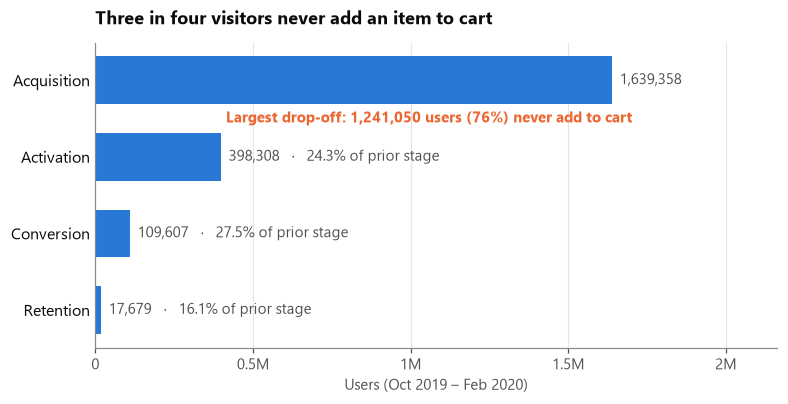

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(funnel))[::-1]
is_leak_target = funnel["stage"] == leak["stage"]

ax.barh(y, funnel["users"], height=0.62, color=BLUE)
ax.set_yticks(y, funnel["stage"], fontsize=10.5, color=INK)
ax.xaxis.set_major_locator(mtick.MultipleLocator(500_000))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:g}M" if v else "0"))
ax.set_xlim(0, funnel["users"].max() * 1.32)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Users (Oct 2019 – Feb 2020)")

for yi, row in zip(y, funnel.itertuples()):
    label = f"{row.users:,.0f}"
    if pd.notna(row.conv_from_prev):
        label += f"   ·   {row.conv_from_prev:.1%} of prior stage"
    ax.text(row.users + funnel["users"].max() * 0.015, yi, label, va="center", fontsize=9.5, color=INK_2)

# Call out the largest drop-off
leak_y = y[is_leak_target.values][0]
ax.annotate(f"Largest drop-off: {leak['drop_off']:,.0f} users ({leak['drop_off_pct']:.0%}) never add to cart",
            xy=(funnel["users"].iloc[1] * 1.04, leak_y + 0.5), fontsize=9.5, color=ORANGE,
            fontweight="bold", va="center")
ax.set_title("Three in four visitors never add an item to cart")
save(fig, "01_funnel")
plt.show()

### 3.2 Monthly funnel

The overall funnel counts each user once over 5 months. To size a monthly opportunity we need the same funnel **per calendar month**: users active in the month, the share who added to cart that month, and the share of those who purchased that month.

In [8]:
user_month_actions = (
    events.loc[events["event_type"].isin(["view", "cart", "purchase"]), ["month", "user_id", "event_type"]]
    .drop_duplicates()
    .assign(flag=1)
    .pivot_table(index=["month", "user_id"], columns="event_type", values="flag",
                 aggfunc="max", fill_value=0, observed=True)
)
active_users_per_month = events.groupby("month")["user_id"].nunique()

monthly_funnel = pd.DataFrame({
    "acquired": active_users_per_month,
    "activated": user_month_actions.groupby("month")["cart"].sum(),
    "converted": (user_month_actions["cart"] & user_month_actions["purchase"]).groupby("month").sum(),
})
monthly_funnel["visit_to_cart"] = monthly_funnel["activated"] / monthly_funnel["acquired"]
monthly_funnel["cart_to_purchase"] = monthly_funnel["converted"] / monthly_funnel["activated"]
monthly_funnel["visit_to_purchase"] = monthly_funnel["converted"] / monthly_funnel["acquired"]
monthly_funnel.loc["Average"] = monthly_funnel.mean()
monthly_funnel.loc["Average", ["visit_to_cart", "cart_to_purchase", "visit_to_purchase"]] = (
    monthly_funnel.loc["Average", "activated"] / monthly_funnel.loc["Average", "acquired"],
    monthly_funnel.loc["Average", "converted"] / monthly_funnel.loc["Average", "activated"],
    monthly_funnel.loc["Average", "converted"] / monthly_funnel.loc["Average", "acquired"],
)
monthly_funnel.style.format({"acquired": "{:,.0f}", "activated": "{:,.0f}", "converted": "{:,.0f}",
                             "visit_to_cart": "{:.1%}", "cart_to_purchase": "{:.1%}", "visit_to_purchase": "{:.1%}"})

,acquired,activated,converted,visit_to_cart,cart_to_purchase,visit_to_purchase
month,,,,,,
2019-10,"399,664","133,818","25,423",33.5%,19.0%,6.4%
2019-11,"368,232","95,939","31,103",26.1%,32.4%,8.4%
2019-12,"370,154","83,458","25,290",22.5%,30.3%,6.8%
2020-01,"410,073","92,653","27,873",22.6%,30.1%,6.8%
2020-02,"391,055","89,269","25,364",22.8%,28.4%,6.5%
Average,"387,836","99,027","27,011",25.5%,27.3%,7.0%


**October is an outlier.** Its visit→cart rate (33.5%) is ~10pp above every later month, yet its cart→purchase rate (19.0%) is ~10pp *below* — and end-to-end visit→purchase stays in a narrow 6.4–8.4% band across all five months. October's extra carts did not produce extra purchasers. Whatever caused it (a promotion that drove speculative carting, or a change in how `cart` was logged), it is direct evidence that **a higher cart rate does not automatically carry through to purchases**. That shapes how the activation opportunity is sized and measured in sections 6 and 7.

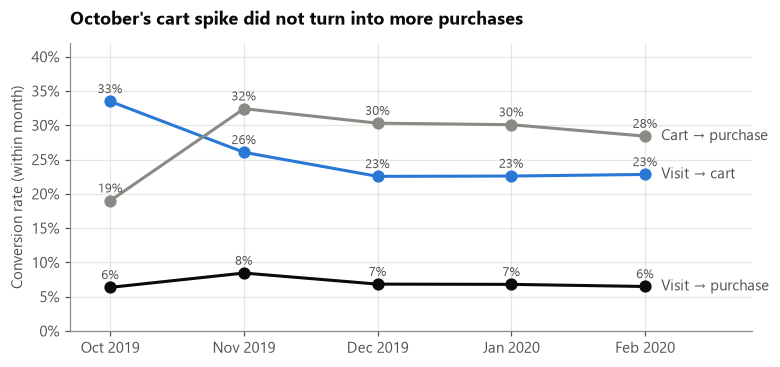

In [9]:
mf = monthly_funnel.drop(index="Average")
labels = [p.strftime("%b %Y") for p in mf.index]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(labels, mf["visit_to_cart"], color=BLUE, lw=2, marker="o", ms=7)
ax.plot(labels, mf["cart_to_purchase"], color=INK_3, lw=2, marker="o", ms=7)
ax.plot(labels, mf["visit_to_purchase"], color=INK, lw=2, marker="o", ms=7)
for series, color, name in [(mf["visit_to_cart"], BLUE, "Visit → cart"), (mf["cart_to_purchase"], INK_3, "Cart → purchase"),
                            (mf["visit_to_purchase"], INK, "Visit → purchase")]:
    ax.text(len(labels) - 1 + 0.12, series.iloc[-1], name, color=INK_2, va="center", fontsize=9.5)
    for i, v in enumerate(series):
        ax.text(i, v + 0.012, f"{v:.0%}", ha="center", fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.42)
ax.set_xlim(-0.3, len(labels) - 0.2)
ax.set_ylabel("Conversion rate (within month)")
ax.set_title("October's cart spike did not turn into more purchases")
save(fig, "02_monthly_conversion_rates")
plt.show()

## 4. Cohort retention

Customers are grouped by the **calendar month of their first purchase** in the data. For each cohort, retention in month *k* = share of the cohort that purchased again *k* months after their first-purchase month (M0 = 100% by definition).

**Window constraint:** the data covers five months, so the October cohort can be followed to M4 and the February cohort only to M0. The matrix therefore runs M0–M4; M5 and M6 cannot be observed in this dataset. Cells after a cohort's observable horizon are left blank rather than shown as zero.

All purchasers are included (not only funnel-converted users), since cohort membership depends on purchasing alone.

In [10]:
customer_lines = revenue_lines[["user_id", "month", "price", "user_session"]].copy()
first_purchase_month = customer_lines.groupby("user_id")["month"].min().rename("cohort")
customer_lines = customer_lines.join(first_purchase_month, on="user_id")

def months_between(later, earlier):
    return (later.dt.year - earlier.dt.year) * 12 + (later.dt.month - earlier.dt.month)

customer_lines["months_since_first"] = months_between(customer_lines["month"], customer_lines["cohort"])

cohort_active = (
    customer_lines
    .groupby(["cohort", "months_since_first"])["user_id"].nunique()
    .unstack("months_since_first")
)
cohort_size = cohort_active[0].astype(int).rename("customers")
retention = cohort_active.div(cohort_size, axis=0)
retention.columns = [f"M{c}" for c in retention.columns]
retention.index = retention.index.strftime("%b %Y")

retention.assign(customers=cohort_size.values).style.format(
    {**{c: "{:.1%}" for c in retention.columns}, "customers": "{:,.0f}"}, na_rep="")

,M0,M1,M2,M3,M4,customers
cohort,,,,,,
Oct 2019,100.0%,18.5%,12.8%,13.2%,10.4%,"25,762"
Nov 2019,100.0%,9.8%,10.1%,7.9%,,"26,761"
Dec 2019,100.0%,8.5%,6.5%,,,"19,702"
Jan 2020,100.0%,8.9%,,,,"20,427"
Feb 2020,100.0%,,,,,"17,866"


### 4.1 Month-1 retention

M1 retention is the earliest repeat signal a growth team can act on — it is observable 30–60 days after acquisition, and it is where the steepest decay happens.

In [11]:
m1 = retention["M1"].dropna()
m1_customers = cohort_size.iloc[: len(m1)]
M1_WEIGHTED = (m1 * m1_customers.values).sum() / m1_customers.sum()

print("M1 retention by cohort:")
print(m1.map("{:.1%}".format).to_string())
print(f"\nCustomer-weighted M1 retention (Oct–Jan cohorts): {M1_WEIGHTED:.1%}")
print(f"Excluding Oct (left-censored, see note below): {(m1.iloc[1:] * m1_customers.iloc[1:].values).sum() / m1_customers.iloc[1:].sum():.1%}")

M1 retention by cohort:
cohort
Oct 2019    18.5%
Nov 2019     9.8%
Dec 2019     8.5%
Jan 2020     8.9%

Customer-weighted M1 retention (Oct–Jan cohorts): 11.7%
Excluding Oct (left-censored, see note below): 9.1%


**Note on the October cohort.** The log starts on 1 Oct 2019, so "first purchase in the data" is not "first purchase ever". October's cohort necessarily contains established repeat customers who happened to buy in October, which inflates its retention. The November–January cohorts are the cleaner read.

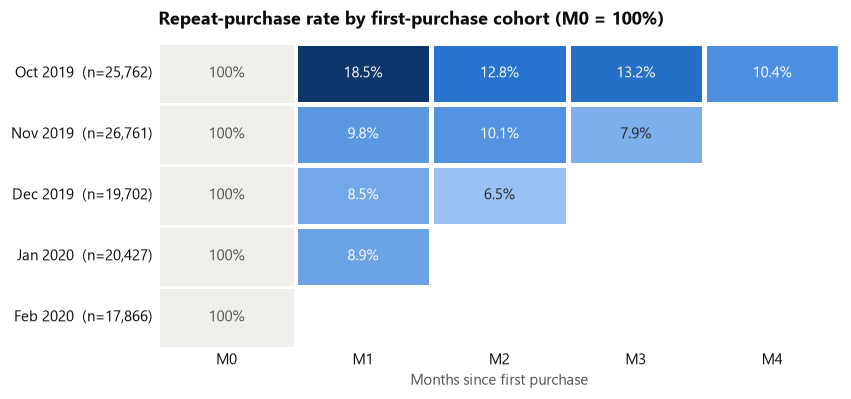

In [12]:
heat = retention.copy()
heat_display = heat.copy()
heat_display["M0"] = np.nan                   # M0 is 100% by definition — keep it out of the colour scale

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(
    heat_display, ax=ax, cmap=sns.blend_palette(["#eef4fc", "#9ec5f4", "#2a78d6", "#0d366b"], as_cmap=True),
    vmin=0, vmax=np.nanmax(heat_display.values), annot=True, fmt=".1%", annot_kws={"fontsize": 10},
    linewidths=2, linecolor="white", cbar=False,
)
for row in range(len(heat)):                  # draw M0 as neutral grey cells
    ax.add_patch(plt.Rectangle((0, row), 1, 1, facecolor="#f0efec", edgecolor="white", lw=2))
    ax.text(0.5, row + 0.5, "100%", ha="center", va="center", fontsize=10, color=INK_2)
ax.set_yticklabels([f"{idx}  (n={n:,})" for idx, n in zip(heat.index, cohort_size.values)], rotation=0, color=INK)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.grid(False)
ax.set_title("Repeat-purchase rate by first-purchase cohort (M0 = 100%)")
ax.set_xticklabels(ax.get_xticklabels(), color=INK)
save(fig, "03_cohort_retention_heatmap")
plt.show()

## 5. Revenue & LTV by cohort

Two views:

1. **Totals over the window** — customers, revenue, revenue per customer, orders per customer. Older cohorts have had more months to spend, so this view is biased toward them.
2. **Cumulative revenue per customer at equal age** (M0, M0–M1, …). This is the fair way to answer *are newer cohorts worth more or less than older ones?*

In [13]:
orders_with_cohort = orders.join(first_purchase_month, on="user_id")

cohort_revenue = (
    orders_with_cohort
    .groupby("cohort")
    .agg(customers=("user_id", "nunique"), orders=("order_value", "size"), revenue=("order_value", "sum"))
)
cohort_revenue["revenue_per_customer"] = cohort_revenue["revenue"] / cohort_revenue["customers"]
cohort_revenue["orders_per_customer"] = cohort_revenue["orders"] / cohort_revenue["customers"]
cohort_revenue["aov"] = cohort_revenue["revenue"] / cohort_revenue["orders"]
cohort_revenue["months_observed"] = [months_between(pd.Series([pd.Period("2020-02", "M")]), pd.Series([c])).iloc[0] + 1
                                     for c in cohort_revenue.index]
cohort_revenue.index = cohort_revenue.index.strftime("%b %Y")
cohort_revenue.style.format({"customers": "{:,.0f}", "orders": "{:,.0f}", "revenue": "${:,.0f}",
                             "revenue_per_customer": "${:,.2f}", "orders_per_customer": "{:.2f}", "aov": "${:,.2f}"})

,customers,orders,revenue,revenue_per_customer,orders_per_customer,aov,months_observed
cohort,,,,,,,
Oct 2019,"25,762","48,103","$2,122,086",$82.37,1.87,$44.12,5
Nov 2019,"26,761","38,613","$1,604,909",$59.97,1.44,$41.56,4
Dec 2019,"19,702","24,916","$909,292",$46.15,1.26,$36.49,3
Jan 2020,"20,427","24,553","$963,154",$47.15,1.20,$39.23,2
Feb 2020,"17,866","19,432","$748,827",$41.91,1.09,$38.54,1


In [14]:
revenue_by_age = (
    customer_lines
    .groupby(["cohort", "months_since_first"])["price"].sum()
    .unstack("months_since_first")
)
cumulative_ltv = revenue_by_age.cumsum(axis=1).div(cohort_size, axis=0)
cumulative_ltv = cumulative_ltv.where(revenue_by_age.notna())     # blank beyond each cohort's horizon
cumulative_ltv.columns = [f"M{c}" for c in cumulative_ltv.columns]
cumulative_ltv.index = cumulative_ltv.index.strftime("%b %Y")
cumulative_ltv.style.format("${:,.2f}", na_rep="")

,M0,M1,M2,M3,M4
cohort,,,,,
Oct 2019,$47.00,$59.52,$66.73,$75.33,$82.37
Nov 2019,$45.15,$49.86,$55.55,$59.97,
Dec 2019,$38.87,$43.04,$46.15,,
Jan 2020,$42.40,$47.15,,,
Feb 2020,$41.91,,,,


In [15]:
ltv_m0 = cumulative_ltv["M0"]
ltv_m1 = cumulative_ltv["M1"].dropna()
print("Cumulative revenue per customer at equal age")
print(f"  M0 (first month):   Oct ${ltv_m0.iloc[0]:.2f} → Feb ${ltv_m0.iloc[-1]:.2f}  "
      f"({ltv_m0.iloc[-1] / ltv_m0.iloc[0] - 1:+.0%})")
print(f"  M0–M1 (two months): Oct ${ltv_m1.iloc[0]:.2f} → Jan ${ltv_m1.iloc[-1]:.2f}  "
      f"({ltv_m1.iloc[-1] / ltv_m1.iloc[0] - 1:+.0%})")
print(f"  M0–M1, Nov vs Jan (excluding left-censored Oct): ${ltv_m1.iloc[1]:.2f} → ${ltv_m1.iloc[-1]:.2f} "
      f"({ltv_m1.iloc[-1] / ltv_m1.iloc[1] - 1:+.0%})")

Cumulative revenue per customer at equal age
  M0 (first month):   Oct $47.00 → Feb $41.91  (-11%)
  M0–M1 (two months): Oct $59.52 → Jan $47.15  (-21%)
  M0–M1, Nov vs Jan (excluding left-censored Oct): $49.86 → $47.15 (-5%)


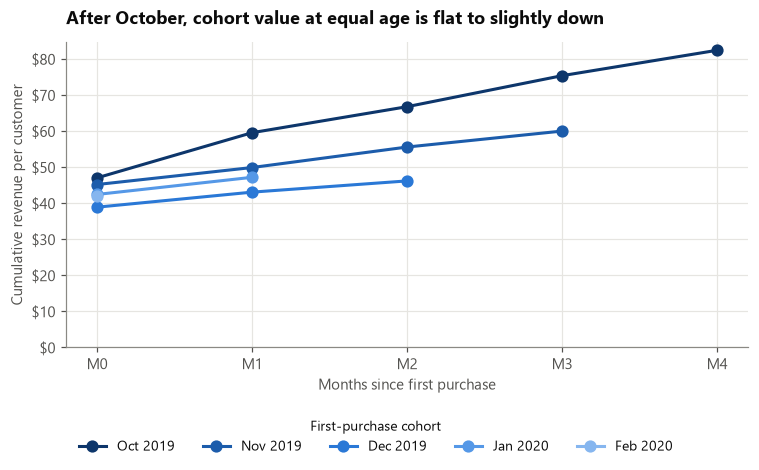

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for (cohort, row), color in zip(cumulative_ltv.iterrows(), BLUE_RAMP[::-1]):
    values = row.dropna()
    x = np.arange(len(values))
    ax.plot(x, values.values, color=color, lw=2, marker="o", ms=7, label=cohort)
ax.set_xticks(range(cumulative_ltv.shape[1]), cumulative_ltv.columns)
ax.set_xlim(-0.2, cumulative_ltv.shape[1] - 0.8)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_ylim(0, None)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cumulative revenue per customer")
ax.legend(title="First-purchase cohort", loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=9, title_fontsize=9, ncol=5)
ax.set_title("After October, cohort value at equal age is flat to slightly down")
save(fig, "04_cohort_cumulative_ltv")
plt.show()

## 6. Opportunity sizing

**Question:** if the highest-leverage conversion rate improved by **5 percentage points**, what would that add per month at current traffic?

Method (all inputs from the monthly funnel in 3.2, averaged across the five months):

1. Extra activated users / month = average monthly acquired users × 5pp
2. Extra purchasers / month = extra activated users × current cart→purchase rate
3. Extra revenue / month = extra purchasers × AOV — counting **one order** per new purchaser, a deliberately conservative choice (repeat orders are excluded)

For comparison the same +5pp is applied to the next stage (cart→purchase), so the reader can see the ranking is not an artefact of the method.

In [17]:
avg = monthly_funnel.loc["Average"]
LIFT = 0.05

def lift_scenario(stage, base_users, base_rate, downstream_rate):
    extra_stage_users = base_users * LIFT
    extra_purchasers = extra_stage_users * downstream_rate
    return {
        "stage lifted": stage,
        "users entering stage / mo": base_users,
        "current rate": base_rate,
        "new rate": base_rate + LIFT,
        "extra users at stage / mo": extra_stage_users,
        "extra purchasers / mo": extra_purchasers,
        "extra revenue / mo": extra_purchasers * AOV,
        "extra revenue / yr": extra_purchasers * AOV * 12,
    }

opportunity = pd.DataFrame([
    lift_scenario("Visit → cart (activation)", avg["acquired"], avg["visit_to_cart"], avg["cart_to_purchase"]),
    lift_scenario("Cart → purchase (conversion)", avg["activated"], avg["cart_to_purchase"], 1.0),
])
baseline_monthly_revenue = orders.groupby("order_month")["order_value"].sum().mean()
opportunity["lift vs baseline revenue"] = opportunity["extra revenue / mo"] / baseline_monthly_revenue

print(f"AOV ${AOV:,.2f}  |  baseline revenue ${baseline_monthly_revenue:,.0f} / month")
opportunity.style.format({
    "users entering stage / mo": "{:,.0f}", "extra users at stage / mo": "{:,.0f}", "current rate": "{:.1%}", "new rate": "{:.1%}",
    "extra purchasers / mo": "{:,.0f}", "extra revenue / mo": "${:,.0f}", "extra revenue / yr": "${:,.0f}",
    "lift vs baseline revenue": "{:+.1%}",
}).hide(axis="index")

AOV $40.79  |  baseline revenue $1,269,654 / month


stage lifted,users entering stage / mo,current rate,new rate,extra users at stage / mo,extra purchasers / mo,extra revenue / mo,extra revenue / yr,lift vs baseline revenue
Visit → cart (activation),"387,836",25.5%,30.5%,"19,392","5,289","$215,772","$2,589,262",+17.0%
Cart → purchase (conversion),"99,027",27.3%,32.3%,"4,951","4,951","$201,987","$2,423,845",+15.9%


**Break-even check.** The two +5pp scenarios land within 7% of each other. The activation estimate assumes the *extra* carters convert at today's average cart→purchase rate. The cell below solves for the rate at which marginal carters would have to convert for an activation lift to beat an equal lift in checkout conversion.

In [18]:
BREAK_EVEN_RATE = avg["activated"] / avg["acquired"]   # 5pp × acquired × r × AOV = 5pp × activated × AOV
print(f"Activation lift out-earns an equal checkout lift only if new carters convert at ≥ {BREAK_EVEN_RATE:.1%} "
      f"(current average: {avg['cart_to_purchase']:.1%}; October, the month with the most carting: "
      f"{monthly_funnel.loc[pd.Period('2019-10', 'M'), 'cart_to_purchase']:.1%})")

Activation lift out-earns an equal checkout lift only if new carters convert at ≥ 25.5% (current average: 27.3%; October, the month with the most carting: 19.0%)


In [19]:
sensitivity = pd.DataFrame({"lift (pp)": [1, 2, 3, 5]})
sensitivity["extra purchasers / mo"] = avg["acquired"] * sensitivity["lift (pp)"] / 100 * avg["cart_to_purchase"]
sensitivity["extra revenue / mo"] = sensitivity["extra purchasers / mo"] * AOV
print("Sensitivity — visit→cart lift")
sensitivity.style.format({"extra purchasers / mo": "{:,.0f}", "extra revenue / mo": "${:,.0f}"}).hide(axis="index")

Sensitivity — visit→cart lift


lift (pp),extra purchasers / mo,extra revenue / mo
1,"1,058","$43,154"
2,"2,116","$86,309"
3,"3,174","$129,463"
5,"5,289","$215,772"


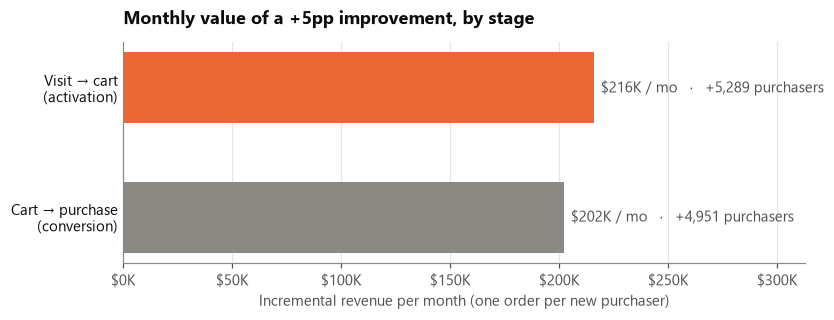

In [20]:
fig, ax = plt.subplots(figsize=(8, 2.6))
names = ["Visit → cart\n(activation)", "Cart → purchase\n(conversion)"]
vals = opportunity["extra revenue / mo"].values
bars = ax.barh(names[::-1], vals[::-1], height=0.55, color=[INK_3, ORANGE])
for b, v, p in zip(bars, vals[::-1], opportunity["extra purchasers / mo"].values[::-1]):
    ax.text(v + vals.max() * 0.015, b.get_y() + b.get_height() / 2,
            f"${v/1e3:,.0f}K / mo   ·   +{p:,.0f} purchasers", va="center", fontsize=9.5, color=INK_2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}K"))
ax.set_xlim(0, vals.max() * 1.45)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_xlabel("Incremental revenue per month (one order per new purchaser)")
ax.set_title("Monthly value of a +5pp improvement, by stage")
save(fig, "05_opportunity_5pp")
plt.show()

## 7. Diagnosing the activation drop-off

Before proposing fixes, we need to know *who* the non-activated users are. Three questions:

1. **How engaged were they?** Single-view bounces need a different fix from users who browsed many products.
2. **Did they come back?** Users with several sessions who never added to cart are reachable (they are identified by `user_id`) and have already shown intent.
3. **When do activated users activate?** If most first carts happen in a user's first session, the first session is where the product has to win.

In [21]:
views = events[events["event_type"] == "view"]
user_engagement = pd.DataFrame({
    "views": views.groupby("user_id").size(),
    "products_viewed": views.groupby("user_id")["product_id"].nunique(),
    "sessions": events.groupby("user_id")["user_session"].nunique(),
    "active_months": events.groupby("user_id")["month"].nunique(),
}).fillna(0)
user_engagement["activated"] = user_engagement.index.isin(activated)

non_activated = user_engagement[~user_engagement["activated"]]
n_non = len(non_activated)

single_view = (non_activated["views"] <= 1).sum()
high_intent = ((non_activated["products_viewed"] >= 3) & (non_activated["sessions"] >= 2)).sum()
multi_month = (non_activated["active_months"] >= 2).sum()

diagnostics = pd.DataFrame({
    "users": [n_non, single_view, high_intent, multi_month],
}, index=["Non-activated users (never added to cart)",
          "  … with ≤ 1 product view (bounce)",
          "  … viewed ≥ 3 products across ≥ 2 sessions (high intent)",
          "  … active in ≥ 2 different months (returning)"])
diagnostics["share of non-activated"] = diagnostics["users"] / n_non
diagnostics.style.format({"users": "{:,.0f}", "share of non-activated": "{:.1%}"})

,users,share of non-activated
Non-activated users (never added to cart),"1,241,050",100.0%
… with ≤ 1 product view (bounce),"757,628",61.0%
… viewed ≥ 3 products across ≥ 2 sessions (high intent),"126,129",10.2%
… active in ≥ 2 different months (returning),"93,451",7.5%


In [22]:
# Activation rate rises sharply with depth of browsing — which tells us where the product is losing people
depth_bins = [0, 1, 2, 4, 9, np.inf]
depth_labels = ["1", "2", "3–4", "5–9", "10+"]
by_depth = (
    user_engagement[user_engagement["products_viewed"] >= 1]
    .assign(products_viewed_band=lambda d: pd.cut(d["products_viewed"], depth_bins, labels=depth_labels))
    .groupby("products_viewed_band", observed=True)
    .agg(users=("activated", "size"), activation_rate=("activated", "mean"))
)
by_depth["share_of_users"] = by_depth["users"] / by_depth["users"].sum()
by_depth.style.format({"users": "{:,.0f}", "activation_rate": "{:.1%}", "share_of_users": "{:.1%}"})

,users,activation_rate,share_of_users
products_viewed_band,,,
1,"1,006,455",10.9%,63.0%
2,"212,588",18.3%,13.3%
3–4,"147,877",32.9%,9.3%
5–9,"110,689",54.3%,6.9%
10+,"120,145",83.7%,7.5%


In [23]:
# In which session does a user add to cart for the first time?
first_event = events.sort_values("event_time").drop_duplicates("user_id")[["user_id", "user_session"]]
first_cart = (events[events["event_type"] == "cart"]
              .sort_values("event_time").drop_duplicates("user_id")[["user_id", "user_session"]])
first_cart = first_cart.merge(first_event, on="user_id", suffixes=("_cart", "_first"))
FIRST_SESSION_CART_SHARE = (first_cart["user_session_cart"] == first_cart["user_session_first"]).mean()
print(f"Activated users whose first add-to-cart happened in their very first session: {FIRST_SESSION_CART_SHARE:.1%}")

Activated users whose first add-to-cart happened in their very first session: 76.5%


In [24]:
# Cart abandonment context for the next stage
cart_users_not_converted = len(activated) - len(converted)
remove_users = events.loc[events["event_type"] == "remove_from_cart", "user_id"].unique()
print(f"Activated but never purchased: {cart_users_not_converted:,} users "
      f"({cart_users_not_converted / len(activated):.1%} of activated)")
print(f"Activated users who removed an item from cart at least once: "
      f"{pd.Index(remove_users).intersection(activated).size / len(activated):.1%}")

Activated but never purchased: 288,701 users (72.5% of activated)
Activated users who removed an item from cart at least once: 45.2%


### 7.1 What the diagnostics say → recommended interventions

**Findings**
- **The leak is a one-product problem.** 63.0% of users who view a product view exactly one, and they activate at 10.9%. Users who view 3–4 products activate at 32.9%, and 5–9 products at 54.3%. Browsing depth is the strongest correlate of activation in the data.
- **The first session decides.** 76.5% of users who ever add to cart do so in their first session. A user who leaves session one without carting rarely comes back to cart.
- **There is a reachable high-intent segment.** 126,129 non-activated users (10.2%) viewed ≥ 3 products across ≥ 2 sessions and never added anything. They are known users (`user_id`) who have already shown intent twice.
- **Cart rate is not the goal metric.** October shows a +10pp cart rate with no gain in purchasers (section 3.2).

**Interventions**
1. **Turn single-product visits into multi-product visits.** Add "pairs well with" / "complete the routine" modules and quick-add buttons on product pages and listings. Target: move users from the 1-product band (10.9% activation) toward the 2-product band (18.3%). Test as an A/B on landing product pages, because depth may be a symptom of intent rather than its cause.
2. **Browse-abandonment re-engagement for the 126K high-intent non-carters.** Trigger email or push within 24 hours of a second session with ≥ 3 product views and no cart, featuring the products they viewed. Because 76.5% of activation happens in session one, these users are the main second-session pool still worth winning. A holdout group measures true incrementality.
3. **Judge every activation experiment on visit→purchase, with cart rate as a diagnostic only.** Pre-register visit→purchase (6.4–8.4% across all five months) as the primary metric. An activation lift only beats an equal checkout lift if new carters convert at ≥ 25.5%. October's carters converted at 19.0%. Ship only what moves purchases.

## 8. Headline numbers

The single reference table for the memo — every figure cited there appears here.

In [25]:
oct_v2c = monthly_funnel.loc[pd.Period("2019-10", "M"), "visit_to_cart"]
novfeb_v2c = (monthly_funnel.drop(index=["Average", pd.Period("2019-10", "M")])["activated"].sum()
              / monthly_funnel.drop(index=["Average", pd.Period("2019-10", "M")])["acquired"].sum())
act = opportunity.iloc[0]

headline = pd.Series({
    "Events analysed (after de-dup)": f"{len(events):,}",
    "Users acquired": f"{funnel.loc[0, 'users']:,}",
    "Activated (added to cart)": f"{funnel.loc[1, 'users']:,} ({funnel.loc[1, 'conv_from_prev']:.1%})",
    "Converted (purchased)": f"{funnel.loc[2, 'users']:,} ({funnel.loc[2, 'conv_from_prev']:.1%} of activated)",
    "Retained (purchased in ≥2 months)": f"{funnel.loc[3, 'users']:,} ({funnel.loc[3, 'conv_from_prev']:.1%} of converted)",
    "Largest drop-off": f"{LEAK_TRANSITION}: {leak['drop_off']:,.0f} users ({leak['drop_off_pct']:.1%})",
    "Visit→cart, Oct vs Nov–Feb": f"{oct_v2c:.1%} vs {novfeb_v2c:.1%}",
    "AOV": f"${AOV:,.2f}",
    "Avg monthly acquired users": f"{avg['acquired']:,.0f}",
    "Avg monthly visit→cart / cart→purchase": f"{avg['visit_to_cart']:.1%} / {avg['cart_to_purchase']:.1%}",
    "+5pp visit→cart: extra purchasers / mo": f"{act['extra purchasers / mo']:,.0f}",
    "+5pp visit→cart: extra revenue / mo (yr)": f"${act['extra revenue / mo']:,.0f} (${act['extra revenue / yr']:,.0f})",
    "+5pp cart→purchase: extra revenue / mo": f"${opportunity.iloc[1]['extra revenue / mo']:,.0f}",
    "Break-even cart→purchase for new carters": f"{BREAK_EVEN_RATE:.1%}",
    "Oct cart→purchase": f"{monthly_funnel.loc[pd.Period('2019-10', 'M'), 'cart_to_purchase']:.1%}",
    "Monthly visit→purchase range": f"{mf['visit_to_purchase'].min():.1%}–{mf['visit_to_purchase'].max():.1%}",
    "M1 retention, Nov–Jan cohorts": f"{(m1.iloc[1:] * m1_customers.iloc[1:].values).sum() / m1_customers.iloc[1:].sum():.1%}",
    "Cum. revenue/customer M0–M1, Nov vs Jan": f"${ltv_m1.iloc[1]:.2f} vs ${ltv_m1.iloc[-1]:.2f}",
    "Users viewing 1 product: share / activation": f"{by_depth.loc['1', 'share_of_users']:.1%} / {by_depth.loc['1', 'activation_rate']:.1%}",
    "Users viewing 5–9 products: activation": f"{by_depth.loc['5–9', 'activation_rate']:.1%}",
    "Baseline revenue / mo": f"${baseline_monthly_revenue:,.0f}",
    "M1 retention, customer-weighted (Oct–Jan)": f"{M1_WEIGHTED:.1%}",
    "Non-activated users: bounce (≤1 view)": f"{single_view:,} ({single_view / n_non:.1%})",
    "Non-activated users: high intent": f"{high_intent:,} ({high_intent / n_non:.1%})",
    "First cart in first session": f"{FIRST_SESSION_CART_SHARE:.1%}",
})
headline.to_frame("value")

,value
Events analysed (after de-dup),"19,583,742"
Users acquired,"1,639,358"
Activated (added to cart),"398,308 (24.3%)"
Converted (purchased),"109,607 (27.5% of activated)"
Retained (purchased in ≥2 months),"17,679 (16.1% of converted)"
Largest drop-off,"Acquisition → Activation: 1,241,050 users (75.7%)"
"Visit→cart, Oct vs Nov–Feb",33.5% vs 23.5%
AOV,$40.79
Avg monthly acquired users,"387,836"
Avg monthly visit→cart / cart→purchase,25.5% / 27.3%
